# Regresión normal vs Ridge vs Lasso vs Elastic Net
Base: Diabetes (sklearn). Variable a predecir (`target`): progresión de la enfermedad, **cuantitativa**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Leer el dataset (ya viene incluido en sklearn, no hay que descargar nada)
from sklearn.datasets import load_diabetes
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame      # tabla con las 10 variables + target
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [4]:
#Variables: todas las variables vienen ya estanrizadas 
#target: variable a predecir una medida cuantitativa de qué tanto avanzó la enfermedad un año después de las mediciones. 
#Entre más alto el número, más progresó.
#Age: edad del paciente
#Sex: sexo del paciente 
#bmi; indice de masa corporal 
#bp: presion acterial promedio
#s1; colesterol total en sangre
#s2; colesterol LDL, malo
#s3, colesterol HDL, bueno
#s4, relación entre colesterol total y HDL (colesterol total / HDL).
#s5, logaritmo de los triglicéridos (grasas en la sangre).
#s6, nivel de glucosa (azúcar) en la sangre.

In [5]:
# Revisar el tamaño de la base: (filas, columnas)
df.shape

(442, 11)

In [6]:
# Examinar la variable respuesta
df['target'].describe()

count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

In [7]:
# Revisar si hay valores faltantes (si todo sale en 0, no hay faltantes)
df.isnull().sum()

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

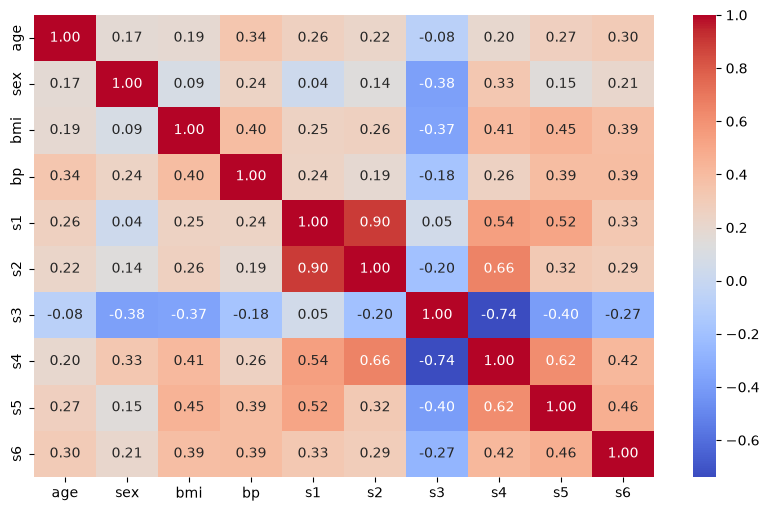

In [8]:
# Matriz de correlaciones: sirve para ver la multicolinealidad (s1 y s2 muy relacionadas)
plt.figure(figsize = (10,6))
sns.heatmap(df.drop(columns = 'target').corr(), annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

In [9]:
# Definir X (variables explicativas) y y (variable a predecir)
X = df.drop('target', axis = 1)
y = df['target']

In [10]:
# Dividir en entrenamiento (70%) y prueba (30%)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 1)

In [11]:
# Función para calcular R2, MAE, MSE y RMSE de cualquier modelo (así no repetimos código)
from sklearn.metrics import r2_score
from sklearn import metrics

def evaluar(modelo):
    y_pred = modelo.predict(X_test)      # predicciones con los datos de prueba
    print("R cuadrado valor:", r2_score(y_test, y_pred))
    print("mean_absolute_error:", metrics.mean_absolute_error(y_test, y_pred))
    print("mean_square_error:", metrics.mean_squared_error(y_test, y_pred))
    print("root_mean_error:", np.sqrt(metrics.mean_squared_error(y_test, y_pred)))
    return r2_score(y_test, y_pred)      # regresamos el R2 para la tabla final

# Diccionario donde guardaremos el R2 de cada modelo
resultados = {}

## 1. Regresión lineal normal

In [12]:
# Regresión lineal
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ -13.3 ,-238.04, 582.22,..., 217.61, 664.56, 46.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,151.4
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [13]:
print("INTERCEPTO:", linreg.intercept_)
print("COEFICIENTES:")
print(pd.Series(linreg.coef_, index = X.columns).round(2))

INTERCEPTO: 151.43052256540983
COEFICIENTES:
age    -13.30
sex   -238.04
bmi    582.22
bp     345.72
s1    -647.57
s2     340.87
s3      90.18
s4     217.61
s5     664.56
s6      46.12
dtype: float64


In [14]:
resultados['Regresión normal'] = evaluar(linreg)

R cuadrado valor: 0.43845439143447806
mean_absolute_error: 41.64919844144017
mean_square_error: 2827.0840174240825
root_mean_error: 53.17033023617667


## 2. Regresión Ridge

In [15]:
# Ridge con alpha = 0 equivale a la regresión lineal normal
from sklearn.linear_model import Ridge
ridgereg = Ridge(alpha = 0)
ridgereg.fit(X_train, y_train)
evaluar(ridgereg)

R cuadrado valor: 0.43845439143447806
mean_absolute_error: 41.64919844144018
mean_square_error: 2827.0840174240825
root_mean_error: 53.17033023617667


0.43845439143447806

In [16]:
# Probamos alpha = 0.1
ridgereg = Ridge(alpha = 0.1)
ridgereg.fit(X_train, y_train)
evaluar(ridgereg)

R cuadrado valor: 0.43762781351032787
mean_absolute_error: 42.0163118891415
mean_square_error: 2831.245398446169
root_mean_error: 53.20944839449258


0.43762781351032787

In [17]:
# Examinar los coeficientes
print(pd.Series(ridgereg.coef_, index = X.columns).round(2))

age      3.08
sex   -196.31
bmi    529.44
bp     306.05
s1     -53.73
s2     -88.67
s3    -174.98
s4     133.27
s5     402.97
s6      78.46
dtype: float64


In [18]:
# Crear un arreglo de valores de alpha
alpha_range = 10.**np.arange(-2,3)
alpha_range

array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [19]:
# Elegir el mejor alpha con RidgeCV
from sklearn.linear_model import RidgeCV
ridgeregcv = RidgeCV(alphas = alpha_range, scoring = 'neg_mean_squared_error')
ridgeregcv.fit(X_train, y_train)
ridgeregcv.alpha_

0.1

In [20]:
# predict usa el mejor alpha
resultados['Ridge'] = evaluar(ridgeregcv)

R cuadrado valor: 0.43762781351032787
mean_absolute_error: 42.01631188914149
mean_square_error: 2831.245398446169
root_mean_error: 53.20944839449258


## 3. Regresión Lasso

In [21]:
# Probamos alpha = 0.001 y examinamos los coeficientes (los que valen 0 fueron eliminados)
from sklearn.linear_model import Lasso
lassoreg = Lasso(alpha = 0.001)
lassoreg.fit(X_train, y_train)
print(pd.Series(lassoreg.coef_, index = X.columns).round(2))

age    -12.50
sex   -236.93
bmi    582.80
bp     344.43
s1    -575.62
s2     286.17
s3      55.42
s4     204.50
s5     638.53
s6      46.39
dtype: float64


In [22]:
# Probamos alpha = 0.01 y examinamos los coeficientes
lassoreg = Lasso(alpha = 0.01)
lassoreg.fit(X_train, y_train)
print(pd.Series(lassoreg.coef_, index = X.columns).round(2))

age     -5.75
sex   -226.37
bmi    588.92
bp     335.38
s1    -214.27
s2       0.00
s3     -96.13
s4     161.18
s5     503.49
s6      46.25
dtype: float64


In [23]:
# R2 y errores para alpha = 0.01
evaluar(lassoreg)

R cuadrado valor: 0.43392255171268534
mean_absolute_error: 41.89544841841969
mean_square_error: 2849.899424492684
root_mean_error: 53.38444927591446


0.43392255171268534

In [24]:
# Elegir el mejor alpha con LassoCV
from sklearn.linear_model import LassoCV
lassoregcv = LassoCV(cv = 5, random_state = 1)
lassoregcv.fit(X_train, y_train)
print('alpha:', lassoregcv.alpha_)

alpha: 0.04832507069308021


In [25]:
# Examinar los coeficientes del mejor Lasso
print(pd.Series(lassoregcv.coef_, index = X.columns).round(2))

age     -0.00
sex   -192.43
bmi    586.83
bp     311.68
s1    -110.56
s2      -0.00
s3    -183.36
s4      36.76
s5     486.24
s6      34.67
dtype: float64


In [26]:
# predict usa el mejor alpha (ahora sí con lassoregcv)
resultados['Lasso'] = evaluar(lassoregcv)

R cuadrado valor: 0.43338126603356397
mean_absolute_error: 42.07224039395544
mean_square_error: 2852.6245105212497
root_mean_error: 53.40996639693054


## 5. Comparación final

In [31]:
# Tabla de R2 de todos los modelos (de mayor a menor)
tabla = pd.DataFrame.from_dict(resultados, orient = 'index', columns = ['R2 en prueba'])
tabla.sort_values('R2 en prueba', ascending = False)

,R2 en prueba
Regresión normal,0.438454
Ridge,0.437628
Elastic Net,0.437210
Lasso,0.433381


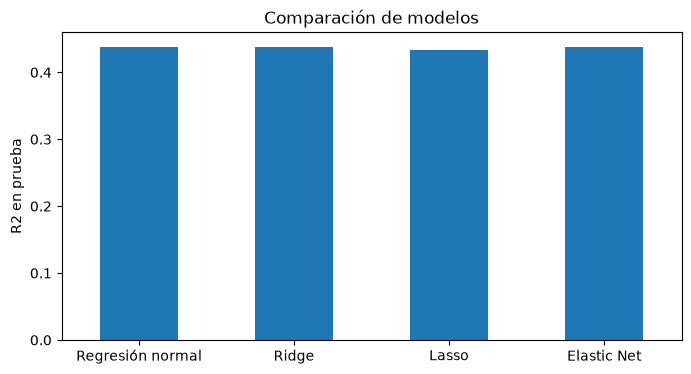

In [30]:
# Gráfica de barras de los R2
tabla.plot(kind = 'bar', legend = False, figsize = (8,4))
plt.ylabel('R2 en prueba')
plt.title('Comparación de modelos')
plt.xticks(rotation = 0)
plt.show()